# PesaPap Customer Growth, Retention and Value Analytics

## Notebook 2: Exploratory Data Analysis

This notebook explores the cleaned PesaPap data using univariate analysis, bivariate analysis, customer segmentation and cohort retention.

The analysis focuses on:

- customer acquisition channels
- geographic performance
- product performance
- customer value and activity
- customer segments
- retention over time


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Detect project root
cwd = Path.cwd()

if (cwd / "data").exists() and (cwd / "src").exists():
    ROOT = cwd
elif (cwd.parent / "data").exists() and (cwd.parent / "src").exists():
    ROOT = cwd.parent
elif Path("/content/drive/MyDrive/plp-capstone-B-robin-kinyua").exists():
    ROOT = Path("/content/drive/MyDrive/plp-capstone-B-robin-kinyua")
else:
    raise FileNotFoundError(
        "Project root not found. Run from the repository root "
        "or notebooks folder."
    )

PROCESSED = ROOT / "data" / "processed"

users = pd.read_csv(
    PROCESSED / "users_clean.csv",
    parse_dates=["signup_date"]
)

transactions = pd.read_csv(
    PROCESSED / "transactions_clean.csv",
    parse_dates=["txn_date"]
)

activity = pd.read_csv(
    PROCESSED / "activity_clean.csv"
)

print("Users:", users.shape)
print("Transactions:", transactions.shape)
print("Activity:", activity.shape)


Users: (8000, 5)
Transactions: (70824, 7)
Activity: (8000, 4)


## 1. Univariate Analysis

This section examines the distribution of individual variables before comparing them with other variables.


Acquisition channel distribution:


,customers
acquisition_channel,
Referral,1942
Social,1818
Agent,1596
Search,1471
Partnership,1173



County distribution:


,customers
county,
Nairobi,2425
Mombasa,1123
Kisumu,985
Nakuru,967
Machakos,909
Nyeri,806
Eldoret,785



Transaction amount summary:


,amount
count,70824.000000
mean,1569.780089
std,1922.212003
min,21.000000
25%,523.000000
50%,988.000000
75%,1900.000000
max,44785.000000


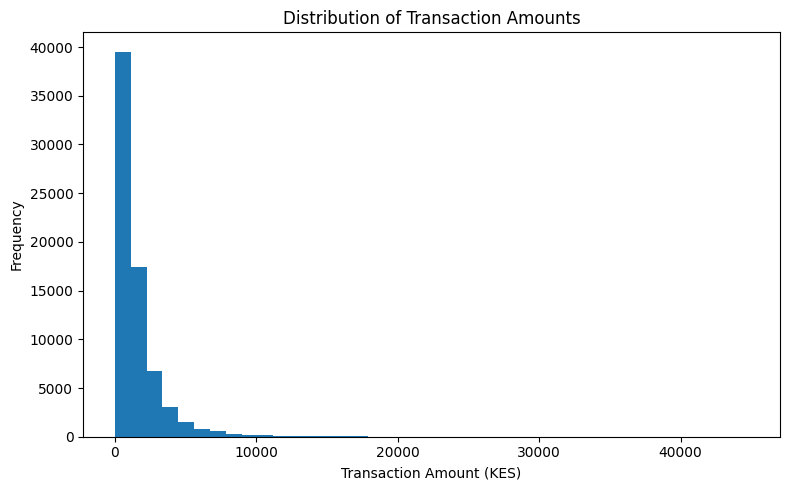

In [2]:
print("Acquisition channel distribution:")
display(
    users["acquisition_channel"]
    .value_counts()
    .rename("customers")
    .to_frame()
)

print("\nCounty distribution:")
display(
    users["county"]
    .value_counts()
    .rename("customers")
    .to_frame()
)

print("\nTransaction amount summary:")
display(
    transactions["amount"]
    .describe()
    .to_frame("amount")
)

transactions["amount"].plot(
    kind="hist",
    bins=40,
    figsize=(8, 5),
    title="Distribution of Transaction Amounts"
)

plt.xlabel("Transaction Amount (KES)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


### Univariate Findings

Referral is the largest acquisition channel with 1,942 customers, while Partnership has the smallest customer base.

Nairobi has the largest customer concentration with 2,425 users. This means total county performance should be interpreted alongside customer count because larger counties naturally have more opportunity to generate transaction value.

Transaction amounts are right-skewed, so both median and mean transaction values are useful when describing customer behaviour.


## 2. Bivariate Analysis

This section compares customer characteristics with transaction activity and value.


,customers,active_users,total_transactions,total_value,avg_value_per_user
acquisition_channel,,,,,
Referral,1942,1847,18473,29028368.0,14947.666323
Social,1818,1707,15002,23555038.0,12956.566557
Agent,1596,1501,13645,21343379.0,13373.044486
Search,1471,1382,13312,20714640.0,14082.012237
Partnership,1173,1085,10392,16536680.0,14097.766411


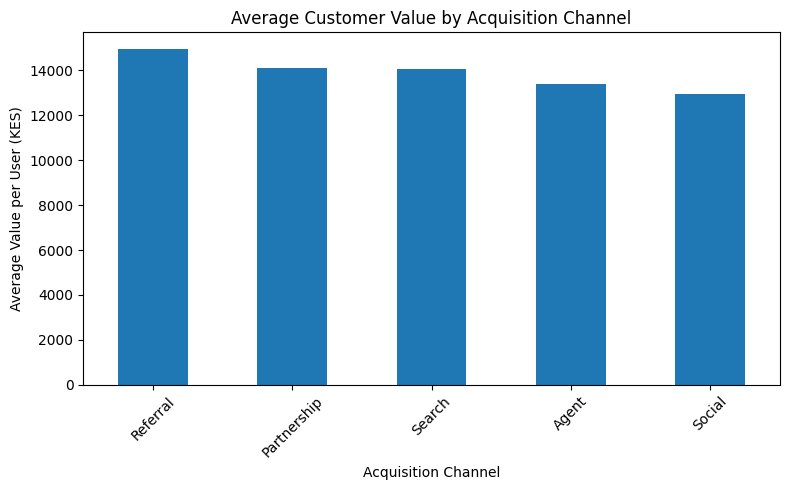

In [3]:
customer_analysis = users.merge(
    activity,
    on="user_id",
    how="left"
)

channel_value = (
    customer_analysis
    .groupby("acquisition_channel")
    .agg(
        customers=("user_id", "count"),
        active_users=("active_flag", "sum"),
        total_transactions=("transaction_count", "sum"),
        total_value=("total_value", "sum"),
        avg_value_per_user=("total_value", "mean")
    )
    .sort_values("total_value", ascending=False)
)

display(channel_value)

channel_value["avg_value_per_user"].sort_values(
    ascending=False
).plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Customer Value by Acquisition Channel"
)

plt.xlabel("Acquisition Channel")
plt.ylabel("Average Value per User (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Acquisition Channel Findings

Referral is the strongest acquisition channel by total customer value, generating approximately **KES 29.03 million**.

Referral also has the highest average value per customer among the largest acquisition channels. Social brings a large number of customers but produces lower average customer value.

This suggests that acquisition decisions should consider both customer volume and customer quality.


,customers,active_users,total_transactions,total_value,avg_value_per_user
county,,,,,
Nairobi,2425,2275,21256,33307748.0,13735.153814
Mombasa,1123,1045,9723,15002566.0,13359.364203
Kisumu,985,933,8719,13838053.0,14048.784772
Nakuru,967,912,8790,13655325.0,14121.328852
Machakos,909,855,8080,12789944.0,14070.345435
Nyeri,806,764,7354,11826199.0,14672.703474
Eldoret,785,738,6902,10758270.0,13704.802548


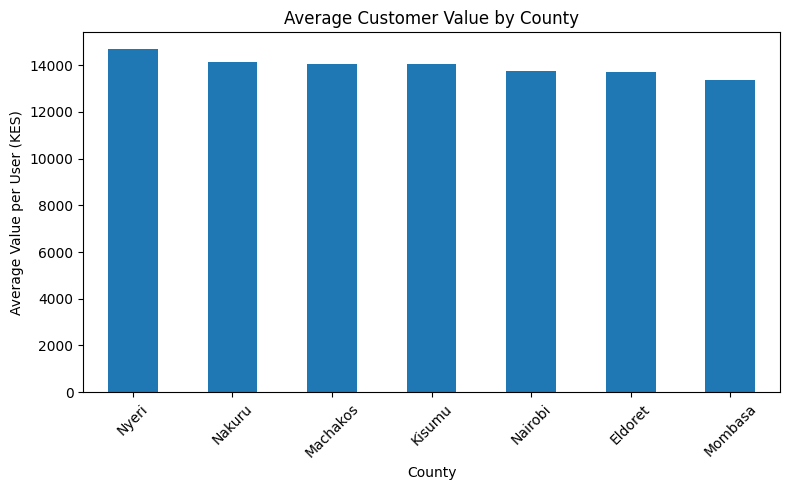

In [4]:
county_value = (
    customer_analysis
    .groupby("county")
    .agg(
        customers=("user_id", "count"),
        active_users=("active_flag", "sum"),
        total_transactions=("transaction_count", "sum"),
        total_value=("total_value", "sum"),
        avg_value_per_user=("total_value", "mean")
    )
    .sort_values("total_value", ascending=False)
)

display(county_value)

county_value["avg_value_per_user"].sort_values(
    ascending=False
).plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Customer Value by County"
)

plt.xlabel("County")
plt.ylabel("Average Value per User (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### County Findings

Nairobi generates the highest total transaction value because it also has the largest customer base.

However, Nyeri has the highest average customer value, followed by other smaller counties such as Nakuru and Machakos.

This shows why market size and customer value should be evaluated separately.


,transactions,total_value,average_transaction
product,,,
Send Money,21043,32978781.0,1567.209096
Airtime,17192,26716946.0,1554.033620
Bill Pay,12861,20296324.0,1578.129539
Merchant Pay,12681,20169924.0,1590.562574
Savings,7047,11016130.0,1563.236838


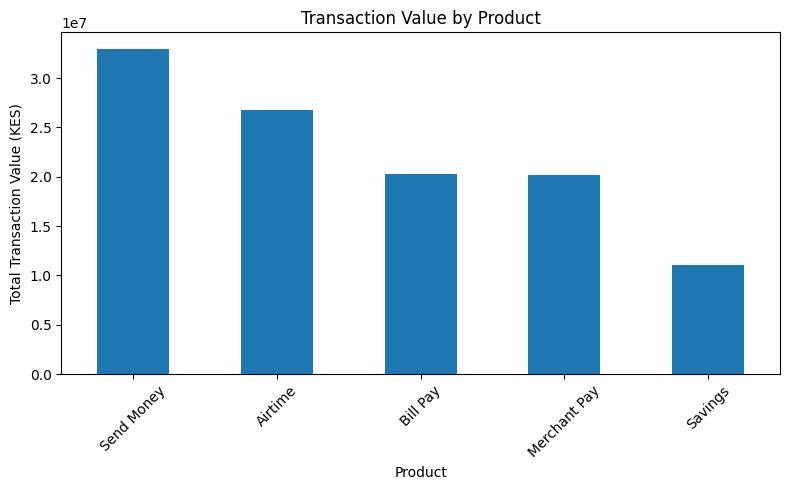

In [5]:
product_performance = (
    transactions
    .groupby("product")
    .agg(
        transactions=("txn_id", "count"),
        total_value=("amount", "sum"),
        average_transaction=("amount", "mean")
    )
    .sort_values("total_value", ascending=False)
)

display(product_performance)

product_performance["total_value"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Transaction Value by Product"
)

plt.xlabel("Product")
plt.ylabel("Total Transaction Value (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Product Findings

Send Money is the strongest product by both transaction volume and transaction value.

It generated approximately **KES 32.98 million** from **21,043 transactions**.

Airtime is the second-largest product, while Savings contributes the lowest transaction volume and total value.


## 3. Customer Segmentation

Customers are segmented using transaction frequency and total customer value.

Active customers are compared with the median frequency and median value. Customers with no valid transactions are classified separately as Inactive.


Frequency median: 9.0
Value median: 12847.0


,customers,transactions,total_value,average_value,value_share_pct
segment,,,,,
High Value,3221,46522,76661483.0,23800.52,68.95
Low Activity,3129,14158,18490355.0,5909.35,16.63
Occasional High Value,540,3564,9448184.0,17496.64,8.50
Frequent Lower Value,632,6580,6578083.0,10408.36,5.92
Inactive,478,0,0.0,0.00,0.00


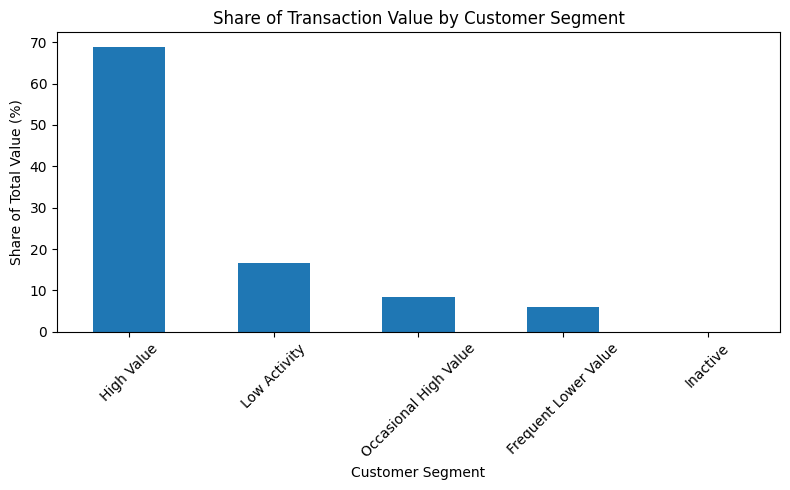

In [6]:
active_customers = customer_analysis[
    customer_analysis["transaction_count"] > 0
].copy()

frequency_median = active_customers[
    "transaction_count"
].median()

value_median = active_customers[
    "total_value"
].median()

print("Frequency median:", frequency_median)
print("Value median:", value_median)

def assign_segment(row):
    if row["transaction_count"] == 0:
        return "Inactive"

    if (
        row["transaction_count"] >= frequency_median
        and row["total_value"] >= value_median
    ):
        return "High Value"

    if (
        row["transaction_count"] >= frequency_median
        and row["total_value"] < value_median
    ):
        return "Frequent Lower Value"

    if (
        row["transaction_count"] < frequency_median
        and row["total_value"] >= value_median
    ):
        return "Occasional High Value"

    return "Low Activity"

customer_analysis["segment"] = customer_analysis.apply(
    assign_segment,
    axis=1
)

segment_summary = (
    customer_analysis
    .groupby("segment")
    .agg(
        customers=("user_id", "count"),
        transactions=("transaction_count", "sum"),
        total_value=("total_value", "sum"),
        average_value=("total_value", "mean")
    )
)

segment_summary["value_share_pct"] = (
    segment_summary["total_value"]
    / segment_summary["total_value"].sum()
    * 100
)

segment_summary = segment_summary.sort_values(
    "total_value",
    ascending=False
)

display(segment_summary.round(2))

segment_summary["value_share_pct"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Share of Transaction Value by Customer Segment"
)

plt.xlabel("Customer Segment")
plt.ylabel("Share of Total Value (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Segmentation Findings

The **High Value** segment contains 3,221 customers and contributes approximately **68.95%** of total transaction value.

The **Low Activity** segment contains more than 3,000 customers but contributes a much smaller share of value.

There are also **478 inactive customers**, creating a clear reactivation opportunity.

The segmentation suggests that PesaPap should protect its High Value customers while separately targeting Low Activity and Inactive users with engagement campaigns.


## 4. Cohort Retention Analysis

Customers are grouped by signup month. Retention measures the percentage of each signup cohort that completes at least one transaction in each month after signup.


In [7]:
cohort_tx = transactions.merge(
    users[["user_id", "signup_date"]],
    on="user_id",
    how="left"
)

cohort_tx["txn_month"] = (
    cohort_tx["txn_date"].dt.to_period("M")
)

cohort_tx["signup_month"] = (
    cohort_tx["signup_date"].dt.to_period("M")
)

cohort_tx["cohort_index"] = (
    cohort_tx["txn_month"] - cohort_tx["signup_month"]
).apply(lambda x: x.n)

monthly_active = (
    cohort_tx
    .groupby(
        ["signup_month", "cohort_index"]
    )["user_id"]
    .nunique()
    .reset_index(name="active_users")
)

cohort_size = (
    users
    .assign(
        signup_month=
        users["signup_date"].dt.to_period("M")
    )
    .groupby("signup_month")["user_id"]
    .nunique()
    .reset_index(name="cohort_size")
)

cohort_counts = monthly_active.merge(
    cohort_size,
    on="signup_month",
    how="left"
)

cohort_counts["retention_rate"] = (
    cohort_counts["active_users"]
    / cohort_counts["cohort_size"]
    * 100
)

retention_matrix = cohort_counts.pivot(
    index="signup_month",
    columns="cohort_index",
    values="retention_rate"
)

retention_matrix.index = (
    retention_matrix.index.astype(str)
)

display(retention_matrix.round(1))


cohort_index,0,1,2,3,4,5,6,7,8,9,10,11
signup_month,,,,,,,,,,,,
2025-07,66.0,59.6,54.5,48.8,50.4,46.8,42.0,36.8,34.0,33.1,38.4,32.1
2025-08,63.1,63.1,54.0,54.6,49.7,49.2,45.0,38.6,34.9,34.7,33.9,NaN
2025-09,63.4,58.2,56.4,48.0,47.0,48.0,43.1,40.7,38.0,32.6,NaN,NaN
2025-10,63.2,61.6,54.3,51.0,49.0,50.3,41.1,38.1,38.1,NaN,NaN,NaN
2025-11,62.2,58.7,54.9,52.9,51.6,46.2,43.9,39.2,NaN,NaN,NaN,NaN
2025-12,64.1,56.8,53.6,51.5,45.2,47.9,43.5,NaN,NaN,NaN,NaN,NaN
2026-01,62.4,55.6,60.9,52.9,50.4,48.8,NaN,NaN,NaN,NaN,NaN,NaN
2026-02,62.1,60.1,55.1,50.0,47.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-03,60.2,60.2,53.6,51.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


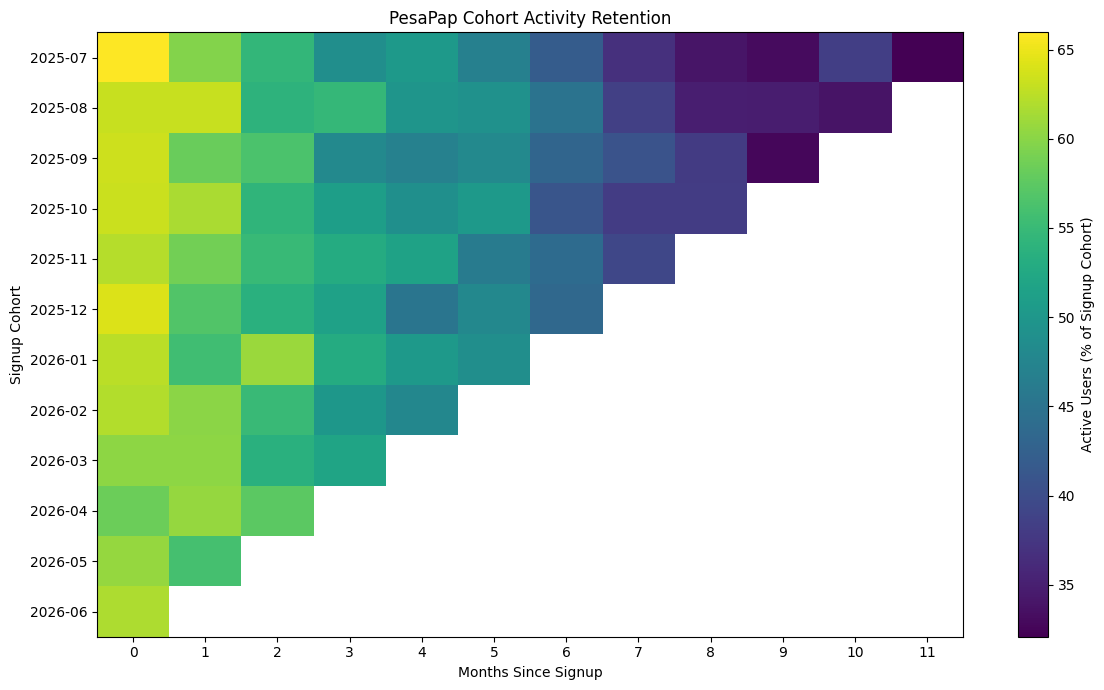

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))

heatmap = ax.imshow(
    retention_matrix,
    aspect="auto"
)

ax.set_title(
    "PesaPap Cohort Activity Retention"
)

ax.set_xlabel("Months Since Signup")
ax.set_ylabel("Signup Cohort")

ax.set_xticks(
    range(len(retention_matrix.columns))
)

ax.set_xticklabels(
    retention_matrix.columns
)

ax.set_yticks(
    range(len(retention_matrix.index))
)

ax.set_yticklabels(
    retention_matrix.index
)

fig.colorbar(
    heatmap,
    ax=ax,
    label="Active Users (% of Signup Cohort)"
)

plt.tight_layout()
plt.show()


### Cohort Retention Findings

Customer activity generally declines as more time passes after signup.

For example, the July 2025 cohort declines from approximately **66.0% active in month 0** to **32.1% by month 11**.

Later cohorts have fewer observable months because the analysis period ends in June 2026. Blank cells therefore represent periods that have not yet been observed rather than zero retention.

The pattern supports introducing lifecycle campaigns after signup to encourage continued transaction activity.


## 5. EDA Summary

The exploratory analysis identifies several important business patterns:

- Referral is the strongest acquisition channel by total customer value.
- Nairobi is the largest market by total activity, while smaller counties such as Nyeri show stronger average value per customer.
- Send Money is the leading product by transaction volume and value.
- High Value customers generate most of PesaPap's transaction value.
- Low Activity and Inactive customers represent important engagement opportunities.
- Customer activity generally declines as cohorts move further from signup.

These findings will be tested and translated into business KPIs, SQL evidence and recommendations in the next notebook.
